# Predicting Patient Readmission Within 30 Days Using Machine Learning
**Name:** Polite Masego Molatlhegi  
**Student ID:** 2805000295  

**Project Workflow**

Data ingestion → data inspection → data processing → EDA → encoding → feature selection → splitting and scaling → multiple-model comparison → evaluation → feature importance → conclusion.

## Contents
1. Introduction
2. Import Libraries
3. Data Ingestion
4. Data Inspection / Understanding
5. Data Processing
6. Exploratory Data Analysis
7. Encoding and Feature Selection
8. Train-Test Split, Scaling and Statistical Checks
9. Model Building: Train Multiple Models
10. Evaluate All Models and the Best Model
11. Feature Importance
12. Key Insights and Conclusion
13. References

## 1. Introduction
Hospital staff need to identify patients who may require closer attention after discharge. This project investigates whether demographic, clinical and admission information can predict recorded patient readmission. A useful model could support discharge planning and prioritisation of follow-up reviews. Whether it can do so must be established through evaluation, rather than assumed from the purpose of the project.

The assessment specifies readmission within 30 days of discharge. This analysis assumes that the supplied Yes/No Readmission label represents that outcome. The CSV contains no dates with which to verify the 30-day interval, and no hospital identifier or documentation establishing the source hospital. Findings therefore refer to the supplied dataset, not verified patterns at a named hospital. Prediction is intended at discharge, when completed length of stay and diagnoses can be available.

Futoma, Morris and Lucas (2015) compared approaches to predicting early hospital readmission. Their study provides a published precedent for comparing prediction models, although its findings cannot be assumed to apply to the present dataset.

The objectives are to prepare and explore the data, select appropriate predictors, compare classification models, and evaluate how well the selected model identifies readmissions. The final discussion explains what the results can tell staff and what remains uncertain.



** Install Packages**

In [0]:
# Install the packages required for this notebook
%pip install pandas numpy matplotlib seaborn scipy scikit-learn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Restart Python to use the installed packages
dbutils.library.restartPython()

## Import Libraries

In [0]:
# Data manipulation
import pandas as pd 

# Numerical Computing
import numpy as np

# Data Preprocessing

#Encode categorical variables
from sklearn.preprocessing import LabelEncoder

#Split the dataset
from sklearn.model_selection import train_test_split

#Scale numerical features
from sklearn.preprocessing import StandardScaler

# Data Visualisation

# Static visualizations
import matplotlib.pyplot as plt

# Statistial visualisations
import seaborn as sns

# Interactive Visualisations
# Plotly is not used by the charts in this version.
# import plotly.express as px

# Compare numeric distributions and test categorical associations
from scipy.stats import mannwhitneyu, chi2_contingency

# Import machine learning models
# Predict the outcome using logistic regression
from sklearn.linear_model import LogisticRegression
# Predict the outcome using a decision tree
from sklearn.tree import DecisionTreeClassifier
# Predict the outcome using random forest and gradient boosting
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
# Predict the outcome using a support vector classifier
from sklearn.svm import SVC
# Predict the outcome using neighbouring training records
from sklearn.neighbors import KNeighborsClassifier
# Predict the outcome using Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Import evaluation metrics
# Measure overall correctness, positive prediction accuracy, recall and F1
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# Display results for each class and count actual versus predicted outcomes
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
# Measure discrimination and calculate the points for an ROC curve
from sklearn.metrics import roc_auc_score, roc_curve


## Data Ingestion

In [0]:
# Indicates the location of the Data
data_path = "/Workspace/Users/molatlhegipolitemasego@gmail.com/Patient Readmission-ML Model/1782926986925_Expanded_Patient_Readmission_Data_(1) (1).csv"
# Reading the data into the notebook as a pandas dataframe
df = pd.read_csv(data_path)
# Displays the first five rows
display(df.head())

Patient ID,Age,Gender,Admission Type,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Readmission
1,62,Female,Elective,4,5,110,130,1,No
2,65,Male,Emergency,19,2,157,81,4,No
3,82,Female,Emergency,18,4,74,84,0,No
4,85,Male,Emergency,2,4,106,85,4,No
5,85,Female,Elective,19,3,80,119,3,No


**Observation**

The data loaded successfully. Each row records a patient and the target is Readmission. The 30-day outcome definition follows the assessment brief; the CSV does not contain dates to verify it independently.

## Data Inspection / Understanding

In [0]:
# Displays the number of rows and columns
print("Rows and columns:", df.shape)
# Displays column names
print("Column names:", df.columns.tolist())
# The info() function provides a concise summary of the DataFrame.
df.info()
# The code generates summary statistics for numerical columns in the DataFrame, including count, mean, standard deviation, minimum value, quartiles (25%, 50%, 75%), and maximum value.
display(df.describe())



Rows and columns: (3000, 10)
Column names: ['Patient ID', 'Age', 'Gender', 'Admission Type', 'Length of Stay', 'Number of Diagnoses', 'Blood Pressure', 'Blood Sugar Levels', 'Previous Admissions', 'Readmission']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Patient ID           3000 non-null   int64 
 1   Age                  3000 non-null   int64 
 2   Gender               3000 non-null   object
 3   Admission Type       3000 non-null   object
 4   Length of Stay       3000 non-null   int64 
 5   Number of Diagnoses  3000 non-null   int64 
 6   Blood Pressure       3000 non-null   int64 
 7   Blood Sugar Levels   3000 non-null   int64 
 8   Previous Admissions  3000 non-null   int64 
 9   Readmission          3000 non-null   object
dtypes: int64(7), object(3)
memory usage: 234.5+ KB


Patient ID,Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
3000.0,3000.0,3000.0,3000.0,3000.0,3000.0,3000.0
1500.5,53.453,15.226333333333333,4.956666666666667,119.058,133.536,1.9583333333333333
866.1697293256098,20.89299635680791,8.264857884289647,2.5750726634335734,34.08926510401445,37.62631105704164,1.4016366923569539
1.0,18.0,1.0,1.0,60.0,51.0,0.0
750.75,35.0,8.0,3.0,89.75,101.0,1.0
1500.5,53.0,15.0,5.0,119.0,133.0,2.0
2250.25,72.0,22.0,7.0,147.25,167.0,3.0
3000.0,89.0,29.0,9.0,179.0,199.0,4.0


**Observation**

The dataset contains 3,000 patient records and 10 original variables. Age ranges from 18 to 89 years. Six numeric predictors describe age, stay length, diagnosis count, clinical measurements and previous admissions. Gender and Admission Type are categorical predictors. Patient ID is an identifier and Readmission is the outcome. Measurement units and collection conditions for blood pressure and blood sugar are not documented in the supplied file.

## Data Processing

In [0]:
# Remove accidental spaces from column names.
df.columns = df.columns.str.strip()
# Check each text column.
for column in ["Gender", "Admission Type", "Readmission"]:
    # Trim category labels, standardise capitalisation and treat empty strings as missing.
    df[column] = df[column].str.strip().str.title().replace("", np.nan)

# Label the missing-value results.
print("Missing values:")
# The code checks for missing values in each column and returns the total number of null values per column.
print(df.isnull().sum())
# The code checks for duplicate rows in the dataset and counts how many repeated records exist.
print("Duplicate rows:", df.duplicated().sum())
# This code is to check the number of unique patients in my data
print("Unique patient IDs:", df["Patient ID"].nunique())
# Check whether the same patient ID appears more than once.
print("Repeated patient IDs:", df["Patient ID"].duplicated().sum())
# Check each text column.
for column in ["Gender", "Admission Type", "Readmission"]:
    # Inspect the actual category labels for inconsistencies.
    print(column, df[column].unique())

# List the numeric predictors.
numeric_columns = ["Age", "Length of Stay", "Number of Diagnoses",
                   # Continue the list of variables or recorded values.
                   "Blood Pressure", "Blood Sugar Levels", "Previous Admissions"]
# Check the smallest and largest recorded values.
display(df[numeric_columns].agg(["min", "max"]))
# Label the negative-value results.
print("Negative values:")
# Count negative measurements or counts that require investigation.
print((df[numeric_columns] < 0).sum())
# Stop if missing values need to be handled.
assert df.isnull().sum().sum() == 0, "Inspect missing values before continuing."
# Stop if duplicate records need to be investigated.
assert df.duplicated().sum() == 0, "Inspect duplicate records before continuing."
# Stop if repeated patients require a different split.
assert df["Patient ID"].is_unique, "Repeated patients need a patient-level split."
# Check that the outcome labels are exactly Yes and No.
assert set(df["Readmission"].unique()) == {"Yes", "No"}


Missing values:
Patient ID             0
Age                    0
Gender                 0
Admission Type         0
Length of Stay         0
Number of Diagnoses    0
Blood Pressure         0
Blood Sugar Levels     0
Previous Admissions    0
Readmission            0
dtype: int64
Duplicate rows: 0
Unique patient IDs: 3000
Repeated patient IDs: 0
Gender ['Female' 'Male']
Admission Type ['Elective' 'Emergency']
Readmission ['No' 'Yes']


Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
18,1,1,60,51,0
89,29,9,179,199,4


Negative values:
Age                    0
Length of Stay         0
Number of Diagnoses    0
Blood Pressure         0
Blood Sugar Levels     0
Previous Admissions    0
dtype: int64


**Observation**

No missing values or duplicate rows were found, and all 3,000 patient IDs are unique. No imputation or row removal is required. Trimming spaces and standardising capitalisation makes the category labels consistent. There are no negative values in the numeric predictors; further clinical plausibility checks require measurement definitions.

Clinical risk categories are omitted from modelling. Blood sugar cannot be labelled diabetic from this file alone because fasting status and units are not established. The original numeric measurements are retained for modelling.

## Exploratory Data Analysis

The analysis asks which recorded characteristics differ between readmitted and non-readmitted patients. The charts and tables are descriptive; they do not establish clinical causes. EDA uses the full supplied sample, so later evaluation is internal to this already-explored dataset.

Patients,Percentage
2134,71.13333333333334
866,28.866666666666667


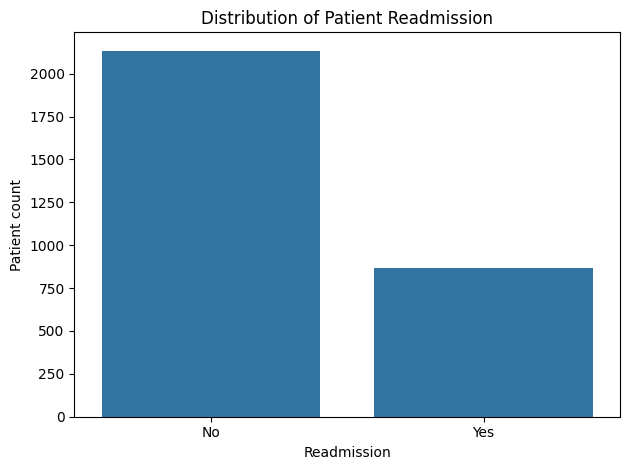

In [0]:
# Count the number of patients by readmission status
counts = df["Readmission"].value_counts()
# Show the number and percentage of patients in each outcome class.
display(pd.DataFrame({"Patients": counts, "Percentage": counts / len(df) * 100}))
# Plot the number of readmitted and non-readmitted patients.
sns.countplot(data=df, x="Readmission", order=["No", "Yes"])
# Give the chart a descriptive title.
plt.title("Distribution of Patient Readmission")
# Label the vertical axis.
plt.ylabel("Patient count")
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()


**Observation**

There are 866 readmissions (28.87%) and 2,134 non-readmissions (71.13%). A classifier can achieve about 71% accuracy while missing every readmission. Saito and Rehmsmeier (2015) highlight the importance of precision and recall in imbalanced classification. These will be examined alongside F1 and ROC-AUC.

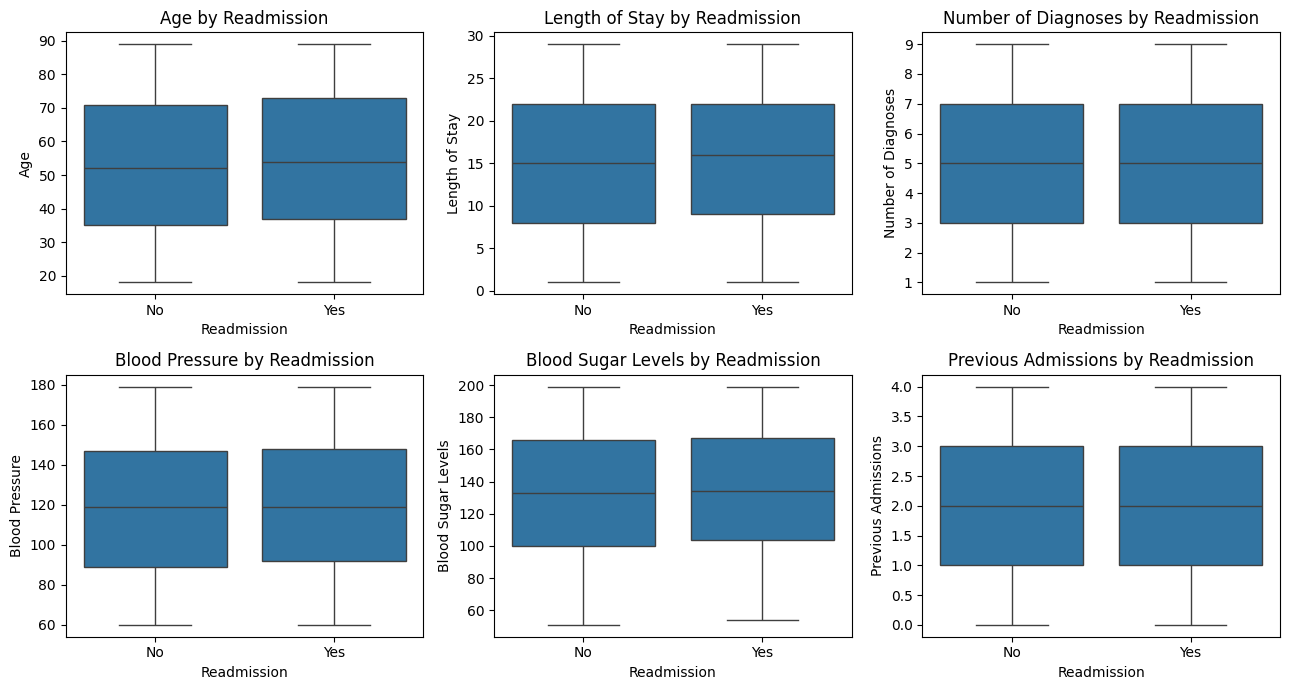

Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions
52.0,15.0,5.0,119.0,133.0,2.0
54.0,16.0,5.0,119.0,134.0,2.0


In [0]:
# List the numeric predictors.
numeric_columns = ["Age", "Length of Stay", "Number of Diagnoses",
                   # Continue the list of variables or recorded values.
                   "Blood Pressure", "Blood Sugar Levels", "Previous Admissions"]
# Arrange six related charts in a two-by-three layout.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
# Place one numeric feature in each chart panel.
for column, ax in zip(numeric_columns, axes.flat):
    # Compare medians, spread and unusual values between the outcome groups.
    sns.boxplot(data=df, x="Readmission", y=column, order=["No", "Yes"], ax=ax)
    # Give this chart panel its title.
    ax.set_title(column + " by Readmission")
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()
# Print group medians to support interpretation of the boxplots.
display(df.groupby("Readmission")[numeric_columns].median())


**Observation**

Readmitted patients have median age 54 versus 52 for non-readmitted patients, and median stay 16 versus 15 days. Median blood sugar is 134 versus 133 in the recorded measurement scale. Both groups have median previous admissions of 2. The boxplots overlap substantially, so these small median differences do not show clear separation. They do not establish statistical significance or show that changing a measurement would prevent readmission.

Admission Type


Patients,Readmissions,Readmission rate (%)
1563,459,29.366602687140116
1437,407,28.322894919972164


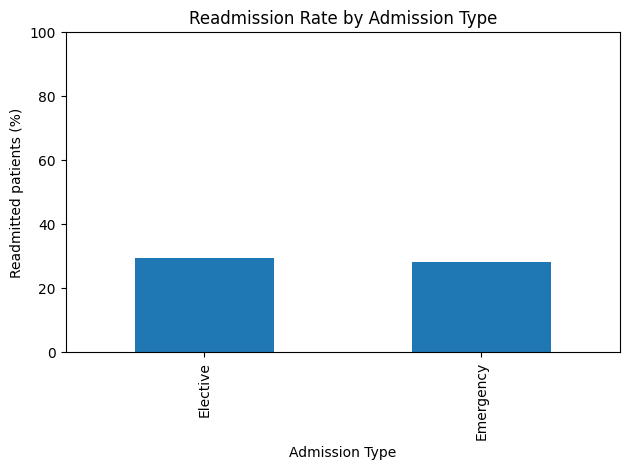

Previous Admissions


Patients,Readmissions,Readmission rate (%)
598,185,30.93645484949833
656,178,27.134146341463417
580,162,27.93103448275862
605,184,30.413223140495866
561,157,27.98573975044563


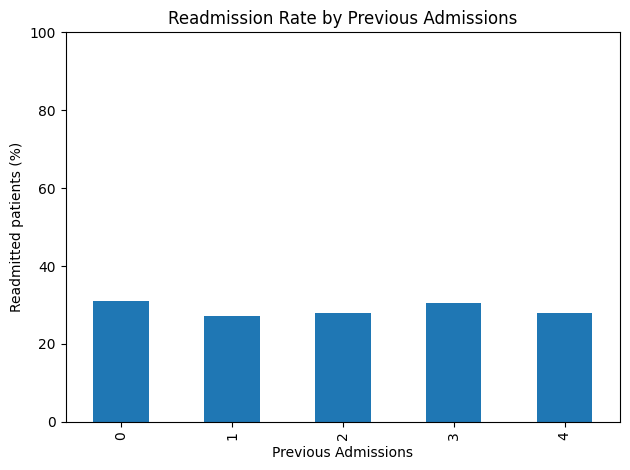

Number of Diagnoses


Patients,Readmissions,Readmission rate (%)
347,107,30.835734870317005
327,89,27.217125382262996
331,105,31.722054380664655
352,93,26.420454545454547
344,86,25.0
310,92,29.677419354838708
339,85,25.073746312684364
335,106,31.64179104477612
315,103,32.698412698412696


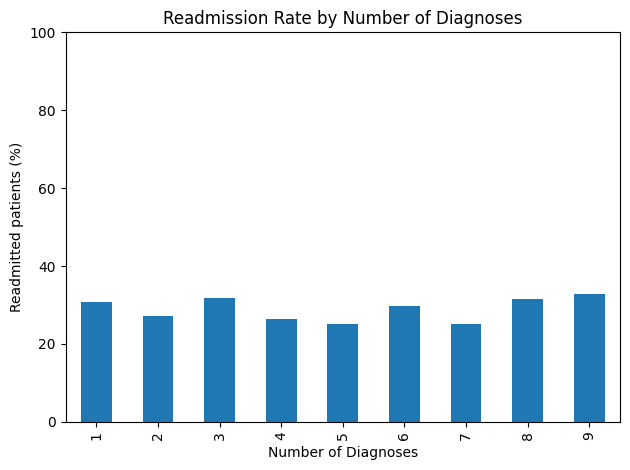

In [0]:
# Repeat the rate calculation for each grouping variable.
for column in ["Admission Type", "Previous Admissions", "Number of Diagnoses"]:
    # Count all patients within each category or recorded count.
    group_counts = df.groupby(column)["Readmission"].count()
    # Count only the patients labelled Yes in each group.
    readmissions = df[df["Readmission"] == "Yes"].groupby(column)["Readmission"].count()
    # Combine group totals and readmission counts into one table.
    rates = pd.DataFrame({"Patients": group_counts,
                          # Store the Readmissions value for this model.
                          "Readmissions": readmissions.reindex(group_counts.index, fill_value=0)})
    # Calculate readmissions divided by patients, multiplied by 100.
    rates["Readmission rate (%)"] = rates["Readmissions"] / rates["Patients"] * 100
    # Show the grouping variable for this table.
    print(column)
    # Display the patient counts and readmission percentages.
    display(rates)
    # Plot the readmission percentage for each group.
    rates["Readmission rate (%)"].plot.bar(title="Readmission Rate by " + column)
    # Label the vertical axis.
    plt.ylabel("Readmitted patients (%)")
    # Use a consistent percentage scale for comparing rate charts.
    plt.ylim(0, 100)
    # Adjust spacing so chart titles and labels fit.
    plt.tight_layout()
    # 7. Display the graph
    plt.show()


**Observation**

Elective admissions have a rate of 29.37%, compared with 28.32% for emergency admissions. Previous-admission groups range from 27.13% to 30.94%, with no consistent increase as previous admissions rise. Diagnosis-count groups also fluctuate rather than increasing steadily. These are descriptive patterns, not confirmed risk factors. For hospital staff, they motivate further investigation rather than justify prioritising a group based on this analysis alone.

## Encoding

Gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Admission Type: {'Elective': np.int64(0), 'Emergency': np.int64(1)}
Readmission: {'No': np.int64(0), 'Yes': np.int64(1)}


Age,Length of Stay,Number of Diagnoses,Blood Pressure,Blood Sugar Levels,Previous Admissions,Gender_encoded,Admission_Type_encoded,Readmission_encoded
1.0,0.0027274017932297973,-0.006421539858106558,-0.005477525668066534,0.0038622340451927987,0.0012710095670961173,-0.010168714734985169,-0.0060038735909915646,0.029498848585996405
0.0027274017932297973,1.0,0.02446354105247697,0.012118650490915529,-0.011461232017391921,-0.007072493745686791,-0.00718084742189333,0.009589493369480933,0.02136405305135995
-0.006421539858106558,0.02446354105247697,1.0,-0.011518912728500802,0.020258758739167503,0.015112546191260557,0.0016539840202591195,-0.0064091310119830215,0.009007511129687285
-0.005477525668066534,0.012118650490915529,-0.011518912728500802,1.0,-0.009829071116697724,0.02769994398619194,-0.033042808911567696,0.004182711501967165,0.010397768833785704
0.0038622340451927987,-0.011461232017391921,0.020258758739167503,-0.009829071116697724,1.0,0.011564054777330158,-0.026200117770929864,0.00983975493412265,0.016675697683119634
0.0012710095670961173,-0.007072493745686791,0.015112546191260557,0.02769994398619194,0.011564054777330158,1.0,0.007041333713838144,-0.009582193848323858,-0.007304929148285224
-0.010168714734985169,-0.00718084742189333,0.0016539840202591195,-0.033042808911567696,-0.026200117770929864,0.007041333713838144,1.0,-0.018488736011817938,0.01490354276616415
-0.0060038735909915646,0.009589493369480933,-0.0064091310119830215,0.004182711501967165,0.00983975493412265,-0.009582193848323858,-0.018488736011817938,1.0,-0.011506165990916663
0.029498848585996405,0.02136405305135995,0.009007511129687285,0.010397768833785704,0.016675697683119634,-0.007304929148285224,0.01490354276616415,-0.011506165990916663,1.0


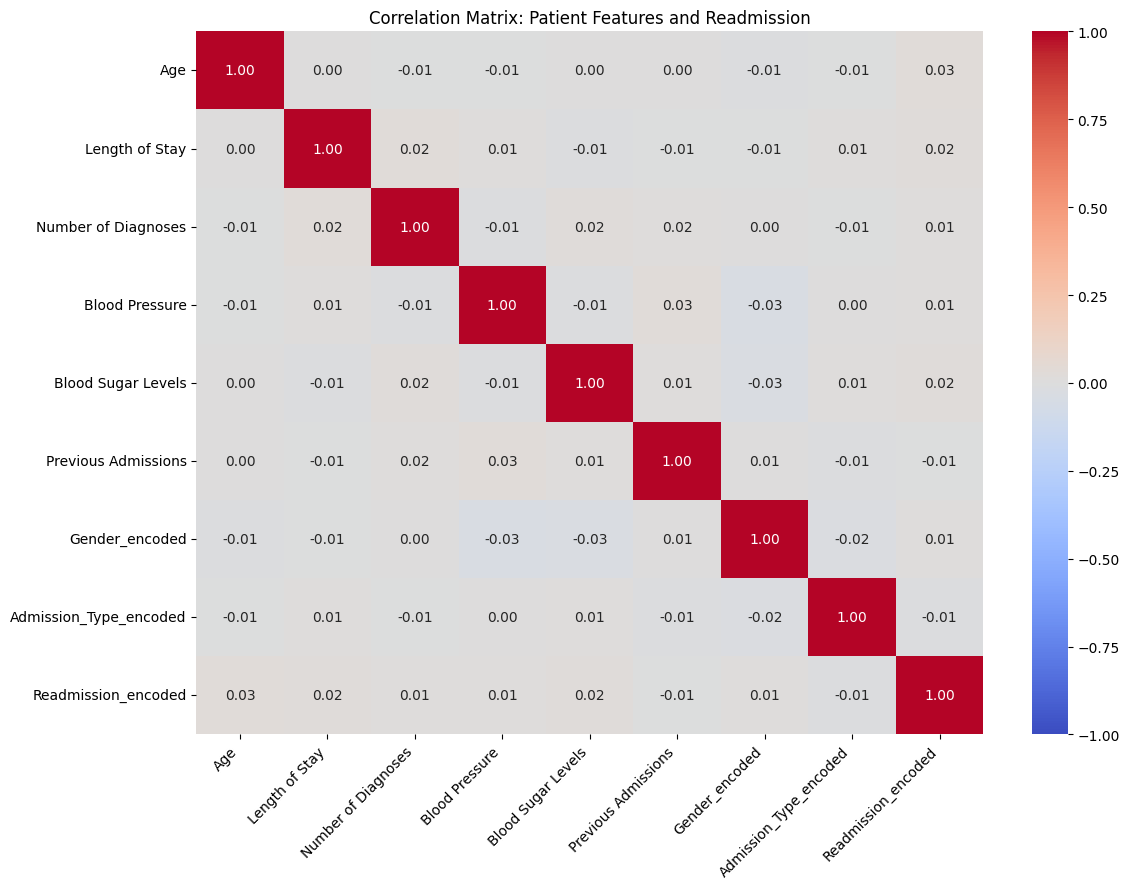

In [0]:
# Create a separate encoder for gender so its mapping is preserved.
gender_encoder = LabelEncoder()
# Create a separate encoder for admission type.
admission_encoder = LabelEncoder()
# Create a separate encoder for the readmission outcome.
target_encoder = LabelEncoder()
# Convert the observed gender categories into numeric codes.
df["Gender_encoded"] = gender_encoder.fit_transform(df["Gender"])
# Convert admission categories into numeric codes.
df["Admission_Type_encoded"] = admission_encoder.fit_transform(df["Admission Type"])
# Convert No and Yes into numeric outcome codes.
df["Readmission_encoded"] = target_encoder.fit_transform(df["Readmission"])
# Show the Gender labels and their numeric codes.
print("Gender:", dict(zip(gender_encoder.classes_, gender_encoder.transform(gender_encoder.classes_))))
# Show the Admission Type labels and their numeric codes.
print("Admission Type:", dict(zip(admission_encoder.classes_, admission_encoder.transform(admission_encoder.classes_))))
# Show the Readmission labels and their numeric codes.
print("Readmission:", dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))
# Confirm that the positive outcome, readmitted, is coded as 1.
assert target_encoder.transform(["Yes"])[0] == 1
# List the eight candidate predictors, excluding Patient ID and the target.
feature_columns = numeric_columns + ["Gender_encoded", "Admission_Type_encoded"]
# Create a modelling table containing those predictors and the encoded target.
df2 = df[feature_columns + ["Readmission_encoded"]].copy()
# Generate matrix
matrix = df2.corr(numeric_only=True)
# Display the correlations between all predictors and the target.
display(matrix)
# Set the chart size so the variable names are readable.
plt.figure(figsize=(12, 9))
# Plot heatmap with values labeled inside the cells
sns.heatmap(matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
# Give the correlation matrix a title.
plt.title("Correlation Matrix: Patient Features and Readmission")
# Keep the horizontal variable labels readable.
plt.xticks(rotation=45, ha="right")
# Keep the vertical variable labels horizontal.
plt.yticks(rotation=0)
# Adjust the spacing around the chart.
plt.tight_layout()
# Display the correlation matrix heatmap.
plt.show()


**Observation**

The three category mappings are printed explicitly, with Yes coded as 1. The full correlation matrix includes all eight predictors and the encoded readmission outcome; Patient ID is excluded. Each cell shows the Pearson correlation between its row and column variables. The diagonal is 1 because each variable is perfectly correlated with itself.

All eight absolute correlations with Readmission_encoded are below .03, showing weak linear association in this sample. Small values displayed as 0.00 are rounded, not necessarily exactly zero. The matrix does not establish statistical significance or causality, and weak linear associations do not rule out nonlinear predictive relationships.


## Feature Selection and Justification
| Variable | Decision and reason |
|---|---|
| Patient ID | Exclude: record identifier with no established transferable meaning |
| Age | Candidate: patient demographic characteristic |
| Gender | Candidate: demographic characteristic; group results also require fairness review |
| Admission Type | Candidate: admission context |
| Length of Stay | Candidate: episode duration known at discharge |
| Number of Diagnoses | Candidate: recorded episode complexity |
| Blood Pressure | Candidate: recorded clinical measurement; meaning depends on measurement definitions |
| Blood Sugar Levels | Candidate: recorded clinical measurement; meaning depends on units and collection conditions |
| Previous Admissions | Candidate: prior hospital utilisation |
| Readmission | Outcome only; exclude from predictor matrix |

Derived age, blood-pressure, sugar, stay and diagnosis categories are omitted from the model because they duplicate existing inputs, discard numeric detail, and some clinical labels are unsupported by the supplied metadata. The original numeric measures are retained.

All eight original predictors are retained for the initial model comparison. The EDA does not provide a strong, consistent basis for removing any of them, and removing variables solely because of weak linear correlations could discard nonlinear information. This is an explicit selection decision, not a claim that all eight are significant predictors. Patient ID and the outcome are excluded from X.

After fitting, tree-based feature importance is used to interpret what the models learned. Strobl et al. (2007) show that random forest importance can be biased when predictors differ in measurement scale or category count. Importance rankings therefore remain exploratory and are not treated as confirmed clinical concerns.

## Train-Test Split

In [0]:
# 2. Specify target (y) and features (X)
# Drop the target column to isolate features
X = df2.drop(columns=["Readmission_encoded"])
# Select only the target column
y = df2["Readmission_encoded"]
# Reserve 20% for testing; stratify preserves class balance and random_state makes the split reproducible.
X_development, X_test, y_development, y_test = train_test_split(
    # Reserve 20% for testing, reproduce the split and preserve class proportions.
    X, y, test_size=0.2, random_state=42, stratify=y)
# Reserve one quarter of development records for validation, giving a 60/20/20 overall split.
X_train, X_validation, y_train, y_validation = train_test_split(
    # Reserve 25% of development records for validation and reproduce the split.
    X_development, y_development, test_size=0.25, random_state=42,
    # Keep approximately the same class proportions in each split.
    stratify=y_development)
# Show the number of training records and predictors.
print("Training:", X_train.shape)
# Show the number of validation records and predictors.
print("Validation:", X_validation.shape)
# Show the number of test records and predictors.
print("Test:", X_test.shape)


Training: (1800, 8)
Validation: (600, 8)
Test: (600, 8)


**Observation**

The data are divided into 1,800 training, 600 validation and 600 test records. Stratification preserves the approximate readmission balance. Models learn from training records; validation records determine the selected algorithm and settings; the test records assess the fixed winner. This separates learning the training sample from generalising to held-out records.

## Scaling

In [0]:
# Initialize and apply StandardScaler
scaler = StandardScaler()
# Fit on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
# Apply the training-based scaling to validation records without refitting.
X_validation_scaled = scaler.transform(X_validation)
# Apply the same training-based scaling to test records without refitting.
X_test_scaled = scaler.transform(X_test)


**Observation**

Scaling is fitted on training data only and then applied to validation and test data. Standardisation helps algorithms sensitive to feature scale, including SVM, KNN and logistic regression. Tree models do not require scaling; the same inputs are used for a consistent comparison.

### Statistical Checks for Feature Selection

The marking requirements ask for feature justification supported by statistical tests. These simple checks use training records only. Two-sided Mann–Whitney U tests compare each numeric variable between the two outcome groups; chi-square tests assess association for Gender and Admission Type. The tests examine univariate association, not causality or multivariable predictive value.

Eight comparisons are made, so a Bonferroni threshold of .05/8 = .00625 is shown alongside the unadjusted p-values. Chi-square expected counts are printed to check whether sparse cells are a concern. These checks inform interpretation; they do not automatically discard features that might contribute through interactions.

In [0]:
# Prepare a list to store the statistical results.
feature_tests = []
# Repeat the test for each numeric predictor.
for column in numeric_columns:
    # Select training values for patients with outcome 0.
    not_readmitted = X_train.loc[y_train == 0, column]
    # Select training values for patients with outcome 1.
    readmitted = X_train.loc[y_train == 1, column]
    # Test for a difference in numeric distributions in either direction.
    statistic, p_value = mannwhitneyu(not_readmitted, readmitted, alternative="two-sided")
    # Store the feature name, test used and p-value.
    feature_tests.append({"Feature": column, "Test": "Mann-Whitney U", "p-value": p_value})
# Check the two categorical predictors separately.
for column in ["Gender_encoded", "Admission_Type_encoded"]:
    # Build a table of category counts by readmission outcome.
    table = pd.crosstab(X_train[column], y_train)
    # Test association and obtain expected counts to check for sparse cells.
    statistic, p_value, degrees_of_freedom, expected = chi2_contingency(table)
    # Store the feature name, test used and p-value.
    feature_tests.append({"Feature": column, "Test": "Chi-square", "p-value": p_value})
    # Show the smallest expected count to check the chi-square test.
    print(column, "minimum expected cell count:", expected.min())
# Put the test results into a readable table.
feature_test_results = pd.DataFrame(feature_tests)
# Use .05/8 to reduce false-positive findings across eight comparisons.
feature_test_results["Below corrected threshold"] = feature_test_results["p-value"] < 0.05 / 8
# Display the tests in order of their p-values.
display(feature_test_results.sort_values("p-value"))


Gender_encoded minimum expected cell count: 253.93333333333334
Admission_Type_encoded minimum expected cell count: 244.9777777777778


Feature,Test,p-value,Below corrected threshold
Age,Mann-Whitney U,0.08105396930912258,false
Admission_Type_encoded,Chi-square,0.10685755205055357,false
Blood Pressure,Mann-Whitney U,0.3723904426188095,false
Number of Diagnoses,Mann-Whitney U,0.4219409422329773,false
Gender_encoded,Chi-square,0.503310930637906,false
Previous Admissions,Mann-Whitney U,0.7572972693935621,false
Blood Sugar Levels,Mann-Whitney U,0.8453861275238856,false
Length of Stay,Mann-Whitney U,0.995366939890179,false


**Observation**

None of the eight training-data tests has a p-value below the corrected .00625 threshold; none is below .05 either. Age has the smallest p-value (.081), which is insufficient evidence at either threshold. Expected cell counts in both chi-square tests are comfortably above 5. These tests do not establish a significant univariate predictor in this sample.

All eight candidate predictors are retained for model comparison because a lack of univariate evidence does not rule out multivariable or nonlinear predictive information. This is a modelling decision supported by the EDA and tests, rather than a claim that these variables are confirmed risk factors.

## Model Building

### Train Multiple Models

Seven classifiers are trained: logistic regression, decision tree, random forest, gradient boosting, SVM, KNN and Naive Bayes. Futoma, Morris and Lucas (2015) provide a published example of comparing models for early hospital readmission, although their results cannot be transferred to this dataset.

Each model is assessed on validation accuracy, precision, recall, F1 and ROC-AUC. F1 for readmitted patients is the primary selection criterion; ROC-AUC breaks ties. Training F1 is included to help identify models that fit training records well but perform poorly on held-out records. All predictions use probability scores with a fixed 0.5 threshold.

Model,Training F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC
Tuned Decision Tree,0.4261501210653753,0.4083333333333333,0.2736318407960199,0.6358381502890174,0.3826086956521739,0.4775283940924043
Tuned Logistic Regression,0.39741750358680056,0.49833333333333335,0.282312925170068,0.4797687861271676,0.3554603854389722,0.48633428544354346
Tuned Random Forest,0.6511627906976745,0.5783333333333334,0.30392156862745096,0.3583815028901734,0.32891246684350134,0.5349460546087098
Decision Tree,1.0,0.56,0.25405405405405407,0.27167630057803466,0.26256983240223464,0.47424564443421635
KNN,0.43544303797468353,0.67,0.345679012345679,0.16184971098265896,0.2204724409448819,0.5474881888697865
Random Forest,1.0,0.6916666666666667,0.2692307692307692,0.04046242774566474,0.07035175879396985,0.5402119911738029
Gradient Boosting,0.2739273927392739,0.6783333333333333,0.16666666666666666,0.028901734104046242,0.04926108374384237,0.5308307725629814
SVM,0.0,0.7116666666666667,0.0,0.0,0.0,0.5321167982022714
Naive Bayes,0.0,0.7116666666666667,0.0,0.0,0.0,0.4986936686927211
Logistic Regression,0.0,0.7116666666666667,0.0,0.0,0.0,0.4864967307874538


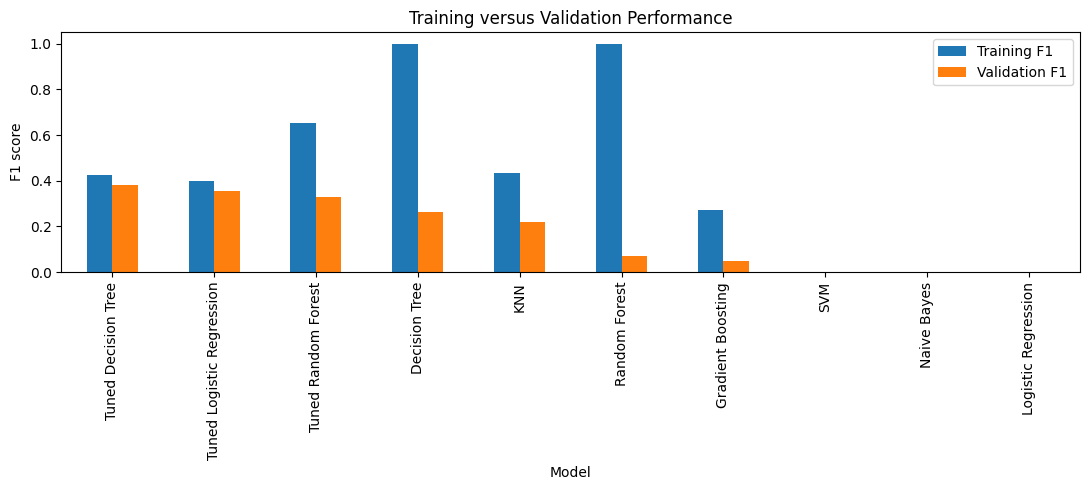

Selected model: Tuned Decision Tree


In [0]:
# Define classification models
models = {
    # Add logistic regression to the model comparison.
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    # Add a decision tree to the model comparison.
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    # Add a random forest to the model comparison.
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    # Add gradient boosting to the model comparison.
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    # Add a support vector classifier and enable probability scores.
    "SVM": SVC(probability=True, random_state=42),
    # Add a nearest-neighbour classifier using five neighbours.
    "KNN": KNeighborsClassifier(n_neighbors=5),
    # Add a Gaussian Naive Bayes classifier.
    "Naive Bayes": GaussianNB()
# Complete this block.
}
# Try stronger regularisation and balanced class weights.
models["Tuned Logistic Regression"] = LogisticRegression(
    # Set regularisation, balance class weights and allow enough fitting iterations.
    C=0.1, class_weight="balanced", max_iter=1000, random_state=42)
# Limit depth and leaf size while giving minority-class records more influence.
models["Tuned Decision Tree"] = DecisionTreeClassifier(
    # Limit tree depth and leaf size, balance class weights and reproduce the result.
    max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=42)
# Try a less flexible forest with balanced class weights.
models["Tuned Random Forest"] = RandomForestClassifier(
    # Set the number of trees, limit complexity and reproduce the result.
    n_estimators=100, max_depth=6, min_samples_leaf=10,
    # Balance class weights and use a fixed random seed.
    class_weight="balanced", random_state=42)

# Evaluate all models
results = []
# Train all models and store results
trained_models = {}
# Train and evaluate models
for name, model in models.items():
    # Learn relationships from training predictors and outcomes.
    model.fit(X_train_scaled, y_train)
    # Save this fitted classifier under its name.
    trained_models[name] = model
    # Estimate positive-class probabilities for training records.
    train_probability = model.predict_proba(X_train_scaled)[:, 1]
    # Convert probabilities of at least .5 into predicted readmissions.
    train_prediction = (train_probability >= 0.5).astype(int)
    # Estimate probabilities for validation patients not used to fit the model.
    validation_probability = model.predict_proba(X_validation_scaled)[:, 1]
    # Apply the same .5 classification threshold to validation scores.
    validation_prediction = (validation_probability >= 0.5).astype(int)
    # Store results
    results.append({"Model": name,
        # Store the Training F1 value for this model.
        "Training F1": f1_score(y_train, train_prediction, zero_division=0),
        # Store the Validation Accuracy value for this model.
        "Validation Accuracy": accuracy_score(y_validation, validation_prediction),
        # Store the Validation Precision value for this model.
        "Validation Precision": precision_score(y_validation, validation_prediction, zero_division=0),
        # Store the Validation Recall value for this model.
        "Validation Recall": recall_score(y_validation, validation_prediction, zero_division=0),
        # Store the Validation F1 value for this model.
        "Validation F1": f1_score(y_validation, validation_prediction, zero_division=0),
        # Store the Validation ROC-AUC value for this model.
        "Validation ROC-AUC": roc_auc_score(y_validation, validation_probability)})
# Create results DataFrame
results_df = pd.DataFrame(results).sort_values(
    # List the columns or options needed for this calculation.
    ["Validation F1", "Validation ROC-AUC"], ascending=False).reset_index(drop=True)
# Display the model comparison table.
display(results_df)
# Compare training and validation F1 visually to look for overfitting.
results_df.plot.bar(x="Model", y=["Training F1", "Validation F1"], figsize=(11, 5))
# Label the vertical axis.
plt.ylabel("F1 score")
# Give the chart a descriptive title.
plt.title("Training versus Validation Performance")
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()
# Identify best model (by F1-Score)
best_model_name = results_df.iloc[0]["Model"]
# Retrieve the selected fitted model without using test labels to choose it.
best_model = trained_models[best_model_name]
# Display the selected model name.
print("Selected model:", best_model_name)



**Observation**

All seven algorithms were trained, together with three explicitly adjusted configurations. The tuned decision tree has the highest validation F1 (.383), followed by tuned logistic regression (.355) and tuned random forest (.329). It is selected by the stated validation F1 rule, with depth limited to 3, minimum leaf size 20 and balanced class weights. Its validation ROC-AUC is only .478, so being the best candidate by F1 does not imply reliable risk ranking.

The default decision tree and random forest have training F1 of 1.000 but validation F1 of .263 and .070 respectively. They fit training outcomes much better than held-out outcomes, indicating overfitting. KNN has the highest validation ROC-AUC among these candidates (.547), but lower F1 (.220) at the fixed threshold. The chosen winner depends on the pre-stated criterion; no algorithm is best on every measure.

Cawley and Talbot (2010) explain that model selection itself can overfit a finite evaluation sample. The held-out test set is therefore used after selecting the candidate. This small comparison is not an exhaustive tuning search or cross-validation.

### Step 3: Model Evaluation

Evaluate each model's performance on the test set using multiple metrics:

- **Accuracy**: Overall correctness
- **Precision**: Of predicted readmissions, how many were correct
- **Recall**: Of actual readmissions, how many were identified
- **F1-Score**: Harmonic mean of precision and recall
- **ROC-AUC**: Ability to distinguish between classes

The candidate was selected using validation F1 in the preceding comparison. The following test results report all models using the same records; they are not used to change that selection. Each model has its metrics, classification report and confusion matrix printed together.


Model: Logistic Regression
Accuracy: 0.7117
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
ROC-AUC: 0.4959
                precision    recall  f1-score   support

Not Readmitted       0.71      1.00      0.83       427
    Readmitted       0.00      0.00      0.00       173

      accuracy                           0.71       600
     macro avg       0.36      0.50      0.42       600
  weighted avg       0.51      0.71      0.59       600



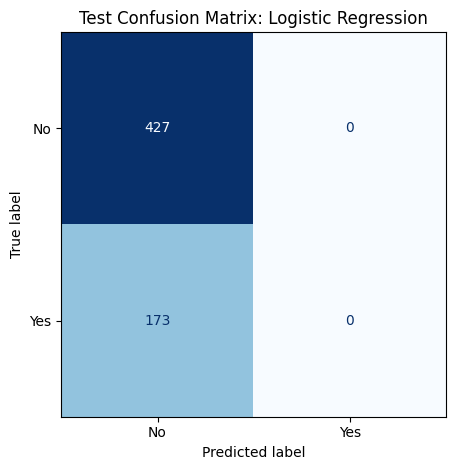

Model: Decision Tree
Accuracy: 0.5833
Precision: 0.3005
Recall: 0.3353
F1-Score: 0.3169
ROC-AUC: 0.5096
                precision    recall  f1-score   support

Not Readmitted       0.72      0.68      0.70       427
    Readmitted       0.30      0.34      0.32       173

      accuracy                           0.58       600
     macro avg       0.51      0.51      0.51       600
  weighted avg       0.60      0.58      0.59       600



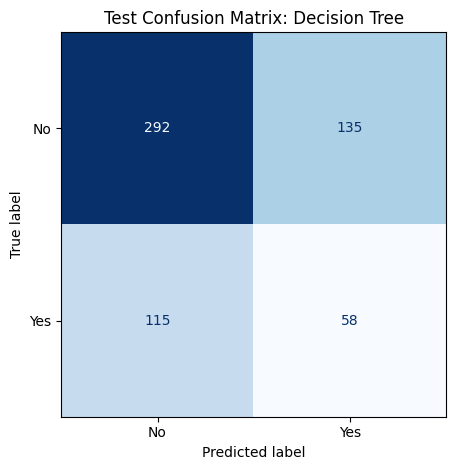

Model: Random Forest
Accuracy: 0.6967
Precision: 0.1538
Recall: 0.0116
F1-Score: 0.0215
ROC-AUC: 0.4907
                precision    recall  f1-score   support

Not Readmitted       0.71      0.97      0.82       427
    Readmitted       0.15      0.01      0.02       173

      accuracy                           0.70       600
     macro avg       0.43      0.49      0.42       600
  weighted avg       0.55      0.70      0.59       600



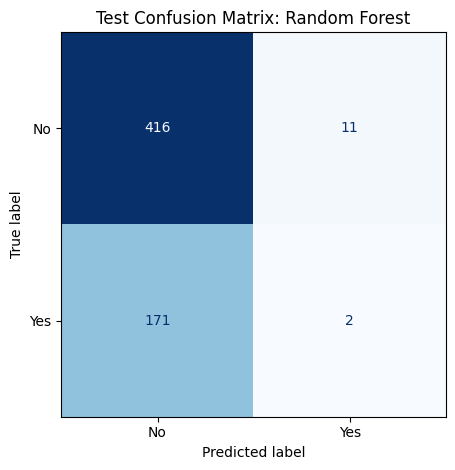

Model: Gradient Boosting
Accuracy: 0.7150
Precision: 0.5556
Recall: 0.0578
F1-Score: 0.1047
ROC-AUC: 0.4997
                precision    recall  f1-score   support

Not Readmitted       0.72      0.98      0.83       427
    Readmitted       0.56      0.06      0.10       173

      accuracy                           0.71       600
     macro avg       0.64      0.52      0.47       600
  weighted avg       0.67      0.71      0.62       600



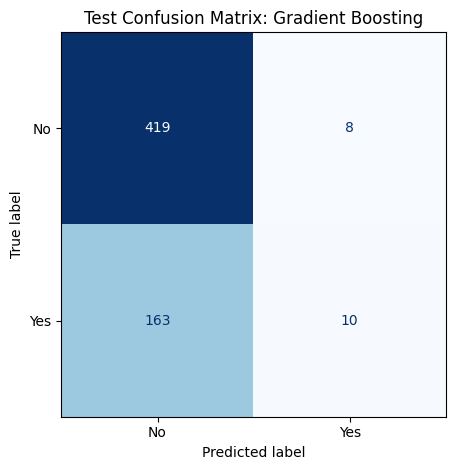

Model: SVM
Accuracy: 0.7117
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
ROC-AUC: 0.5217
                precision    recall  f1-score   support

Not Readmitted       0.71      1.00      0.83       427
    Readmitted       0.00      0.00      0.00       173

      accuracy                           0.71       600
     macro avg       0.36      0.50      0.42       600
  weighted avg       0.51      0.71      0.59       600



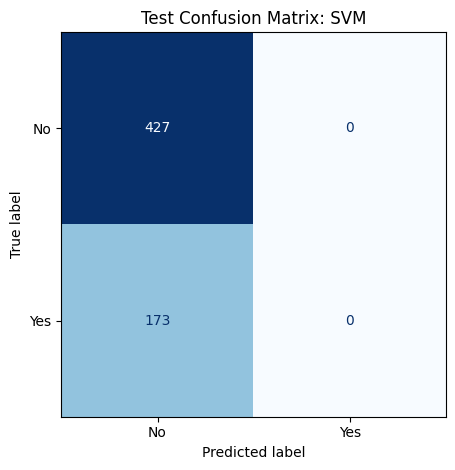

Model: KNN
Accuracy: 0.6550
Precision: 0.2703
Recall: 0.1156
F1-Score: 0.1619
ROC-AUC: 0.4881
                precision    recall  f1-score   support

Not Readmitted       0.71      0.87      0.78       427
    Readmitted       0.27      0.12      0.16       173

      accuracy                           0.66       600
     macro avg       0.49      0.49      0.47       600
  weighted avg       0.58      0.66      0.60       600



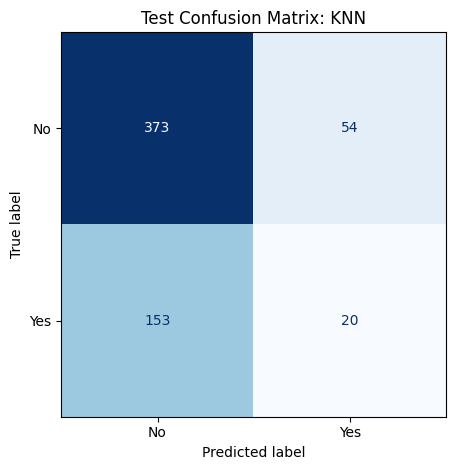

Model: Naive Bayes
Accuracy: 0.7117
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
ROC-AUC: 0.4859
                precision    recall  f1-score   support

Not Readmitted       0.71      1.00      0.83       427
    Readmitted       0.00      0.00      0.00       173

      accuracy                           0.71       600
     macro avg       0.36      0.50      0.42       600
  weighted avg       0.51      0.71      0.59       600



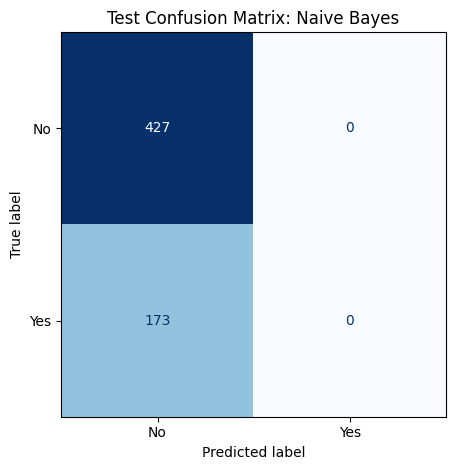

Model: Tuned Logistic Regression
Accuracy: 0.5150
Precision: 0.2878
Recall: 0.4624
F1-Score: 0.3548
ROC-AUC: 0.4958
                precision    recall  f1-score   support

Not Readmitted       0.71      0.54      0.61       427
    Readmitted       0.29      0.46      0.35       173

      accuracy                           0.52       600
     macro avg       0.50      0.50      0.48       600
  weighted avg       0.59      0.52      0.54       600



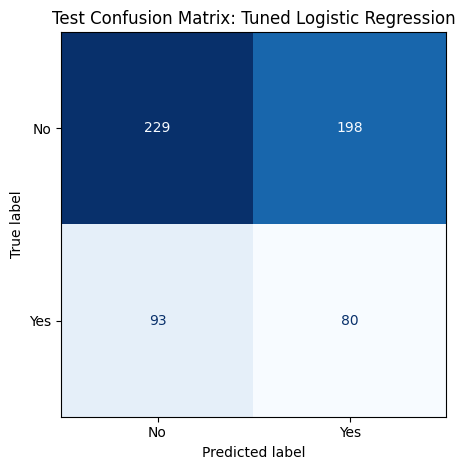

Model: Tuned Decision Tree
Accuracy: 0.4150
Precision: 0.2753
Recall: 0.6301
F1-Score: 0.3831
ROC-AUC: 0.4775
                precision    recall  f1-score   support

Not Readmitted       0.69      0.33      0.44       427
    Readmitted       0.28      0.63      0.38       173

      accuracy                           0.41       600
     macro avg       0.48      0.48      0.41       600
  weighted avg       0.57      0.41      0.43       600



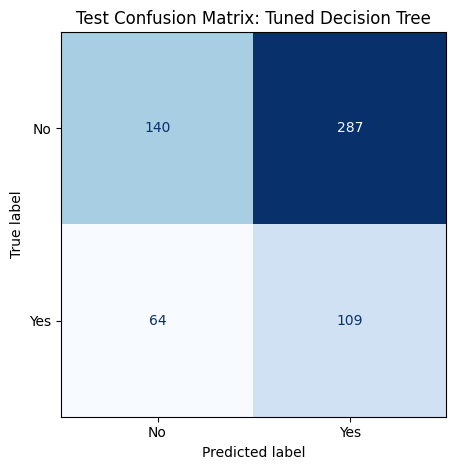

Model: Tuned Random Forest
Accuracy: 0.5600
Precision: 0.2514
Recall: 0.2659
F1-Score: 0.2584
ROC-AUC: 0.4900
                precision    recall  f1-score   support

Not Readmitted       0.70      0.68      0.69       427
    Readmitted       0.25      0.27      0.26       173

      accuracy                           0.56       600
     macro avg       0.47      0.47      0.47       600
  weighted avg       0.57      0.56      0.56       600



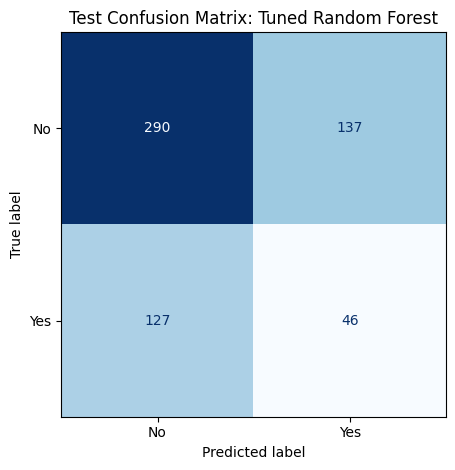

Model,Correct non-readmissions (TN),False alerts (FP),Missed readmissions (FN),Detected readmissions (TP)
Logistic Regression,427,0,173,0
Decision Tree,292,135,115,58
Random Forest,416,11,171,2
Gradient Boosting,419,8,163,10
SVM,427,0,173,0
KNN,373,54,153,20
Naive Bayes,427,0,173,0
Tuned Logistic Regression,229,198,93,80
Tuned Decision Tree,140,287,64,109
Tuned Random Forest,290,137,127,46


Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.7116666666666667,0.0,0.0,0.0,0.4959320978462455
Decision Tree,0.5833333333333334,0.3005181347150259,0.3352601156069364,0.31693989071038253,0.5095504325107281
Random Forest,0.6966666666666667,0.15384615384615385,0.011560693641618497,0.021505376344086023,0.4906526241691597
Gradient Boosting,0.715,0.5555555555555556,0.057803468208092484,0.10471204188481675,0.49972248920415313
SVM,0.7116666666666667,0.0,0.0,0.0,0.5217338333040029
KNN,0.655,0.2702702702702703,0.11560693641618497,0.16194331983805668,0.48806026722259066
Naive Bayes,0.7116666666666667,0.0,0.0,0.0,0.485860486523805
Tuned Logistic Regression,0.515,0.28776978417266186,0.4624277456647399,0.35476718403547675,0.4957696525023352
Tuned Decision Tree,0.415,0.27525252525252525,0.630057803468208,0.38312829525483305,0.47750808842441544
Tuned Random Forest,0.56,0.25136612021857924,0.2658959537572254,0.25842696629213485,0.490043454129496


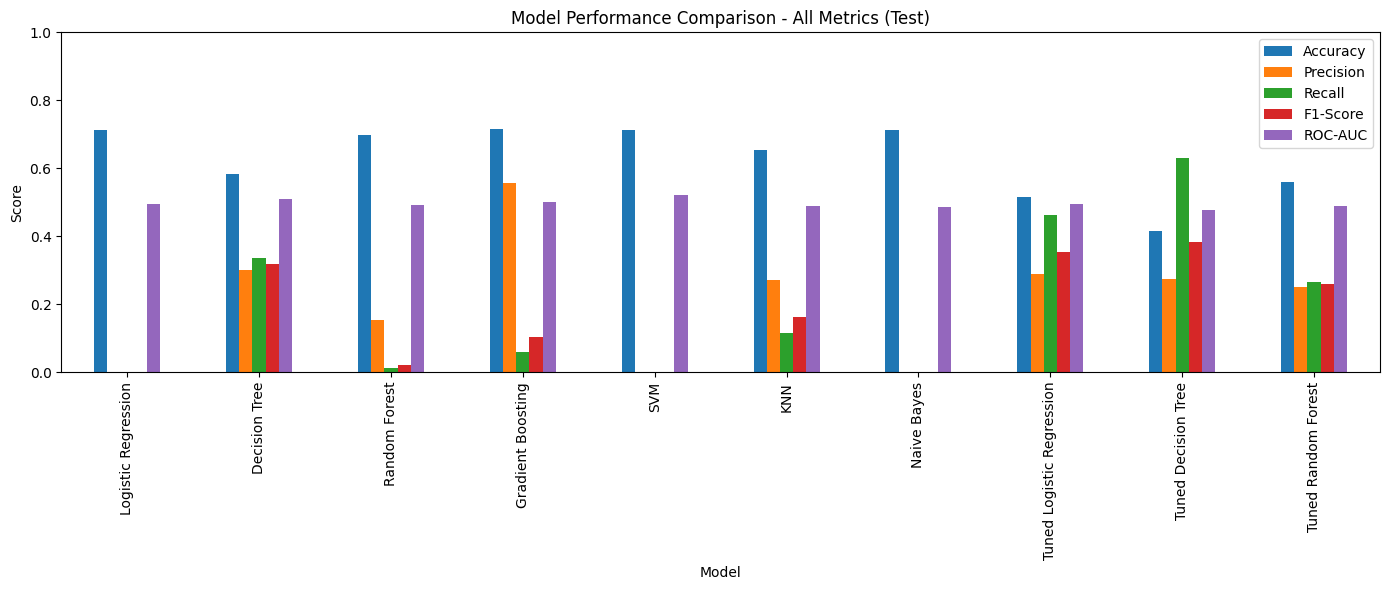

In [0]:
# Prepare a summary of correct predictions, false alerts and missed readmissions.
# Store all five test metrics for every model.
all_test_metrics = []
test_errors = []
# Draw one test confusion matrix for every fitted configuration.
for name, model in trained_models.items():
    # Extract the estimated probability for class 1, readmission.
    probability = model.predict_proba(X_test_scaled)[:, 1]
    # Classify scores using the fixed .5 threshold.
    prediction = (probability >= 0.5).astype(int)
    # Calculate metrics
    accuracy = accuracy_score(y_test, prediction)
    # Calculate how many predicted readmissions were correct.
    precision = precision_score(y_test, prediction, zero_division=0)
    # Calculate how many actual readmissions were detected.
    recall = recall_score(y_test, prediction, zero_division=0)
    # Calculate the balance between precision and recall.
    f1 = f1_score(y_test, prediction, zero_division=0)
    # Calculate discrimination using probability scores, not class labels.
    roc_auc = roc_auc_score(y_test, probability)
    # Store results
    all_test_metrics.append({"Model": name, "Accuracy": accuracy,
        # Store precision, recall, F1 and ROC-AUC for this model.
        "Precision": precision, "Recall": recall, "F1-Score": f1, "ROC-AUC": roc_auc})
    # Identify the model whose results are printed below.
    print("Model:", name)
    # Display overall prediction accuracy.
    print(f"Accuracy: {accuracy:.4f}")
    # Display precision for readmitted patients.
    print(f"Precision: {precision:.4f}")
    # Display recall for readmitted patients.
    print(f"Recall: {recall:.4f}")
    # Display the F1 score for readmitted patients.
    print(f"F1-Score: {f1:.4f}")
    # Display the ROC-AUC score.
    print(f"ROC-AUC: {roc_auc:.4f}")
    # Print classification report
    print(classification_report(y_test, prediction,
        # Name the two outcome classes and display undefined metrics as zero.
        target_names=["Not Readmitted", "Readmitted"], zero_division=0))
    # Count actual-versus-predicted outcomes, with No first and Yes second.
    model_cm = confusion_matrix(y_test, prediction, labels=[0, 1])
    # Unpack correct negatives, false alerts, missed readmissions and detected readmissions.
    model_tn, model_fp, model_fn, model_tp = model_cm.ravel()
    # Store the four outcome counts for this model.
    test_errors.append({"Model": name,
        # Store the Correct non-readmissions (TN) value for this model.
        "Correct non-readmissions (TN)": model_tn,
        # Store the False alerts (FP) value for this model.
        "False alerts (FP)": model_fp,
        # Store the Missed readmissions (FN) value for this model.
        "Missed readmissions (FN)": model_fn,
        # Store the Detected readmissions (TP) value for this model.
        "Detected readmissions (TP)": model_tp})
    # Show counts with actual outcomes on rows and predictions on columns.
    ConfusionMatrixDisplay(model_cm, display_labels=["No", "Yes"]).plot(
        # Show whole-number counts in a blue confusion matrix without a colour bar.
        values_format="d", cmap="Blues", colorbar=False)
    # Give the chart a descriptive title.
    plt.title("Test Confusion Matrix: " + name)
    # Adjust spacing so chart titles and labels fit.
    plt.tight_layout()
    # 7. Display the graph
    plt.show()
# Display the error counts for every model.
display(pd.DataFrame(test_errors))

# Create results DataFrame
all_test_results = pd.DataFrame(all_test_metrics)
# Display all five test metrics for all models in one table.
display(all_test_results)
# Create comparison visualizations
all_test_results.plot.bar(x="Model", y=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"], figsize=(14, 6))
# Give the comparison chart its title.
plt.title("Model Performance Comparison - All Metrics (Test)")
# Label the score axis.
plt.ylabel("Score")
# Keep the score range consistent across metrics.
plt.ylim(0, 1)
# Adjust chart spacing.
plt.tight_layout()
# Display the graph.
plt.show()


**Observation**

Logistic Regression detects 0 of 173 test readmissions, misses 173 and produces 0 false alerts. Decision Tree detects 58 of 173 test readmissions, misses 115 and produces 135 false alerts. Random Forest detects 2 of 173 test readmissions, misses 171 and produces 11 false alerts. Tuned Decision Tree detects 109 of 173 test readmissions, misses 64 and produces 287 false alerts. 

The metrics and matrices describe the same test predictions. ROC-AUC uses probability scores, while precision, recall and F1 use the fixed .5 decision threshold. These comparisons report candidate behaviour; the best-model choice remains based on validation F1.

### ROC Curves for All Models

The curves compare all models' test-set discrimination, with ROC-AUC printed in the legend. This complements the fixed-threshold metrics and confusion matrices. These results are reported after validation-based selection and do not change the chosen candidate.

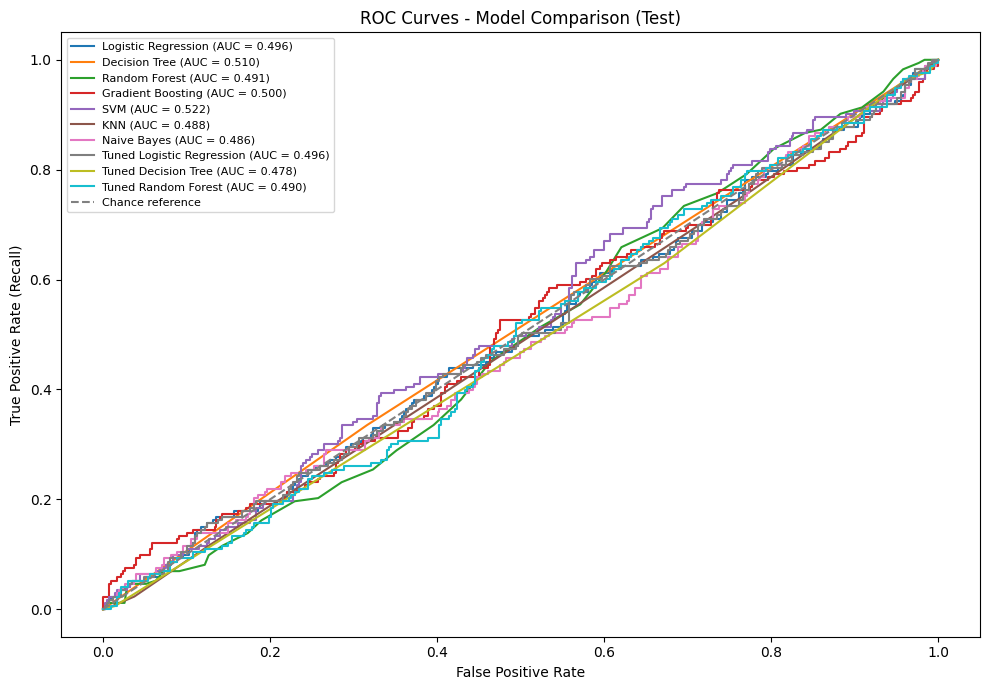

In [0]:
# Plot ROC curves for all models
plt.figure(figsize=(10, 7))
# Use the same test records for each trained model.
for name, model in trained_models.items():
    # Make predictions as positive-class probability scores.
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    # Calculate false-positive and true-positive rates across thresholds.
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
    # Calculate this model's ROC-AUC.
    auc = roc_auc_score(y_test, y_pred_proba)
    # Label each curve with the model name and its ROC-AUC.
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
# Add diagonal line (random classifier)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance reference")
# Label the horizontal axis.
plt.xlabel("False Positive Rate")
# Label the vertical axis.
plt.ylabel("True Positive Rate (Recall)")
# Add the chart title.
plt.title("ROC Curves - Model Comparison (Test)")
# Show the model names and ROC-AUC values.
plt.legend(fontsize=8)
# Adjust chart spacing.
plt.tight_layout()
# Display the graph.
plt.show()


### Evaluate the Best Model

The tuned decision tree is the candidate selected by validation F1. The following section examines its test metrics, classification report, confusion matrix and ROC curve in detail, compares it with constant prediction baselines, and checks performance across training, validation and test records.

Steyerberg et al. (2010) distinguish discrimination, probability calibration and clinical usefulness. Being the selected candidate does not establish clinical usefulness. Always-No precision is undefined and is displayed as zero.


Model,Accuracy,Precision,Recall,F1,ROC-AUC
Selected model,0.415,0.27525252525252525,0.630057803468208,0.38312829525483305,0.47750808842441544
Always No,0.7116666666666667,0.0,0.0,0.0,0.5
Always Yes,0.28833333333333333,0.28833333333333333,1.0,0.4476067270375162,0.5


                precision    recall  f1-score   support

Not readmitted       0.69      0.33      0.44       427
    Readmitted       0.28      0.63      0.38       173

      accuracy                           0.41       600
     macro avg       0.48      0.48      0.41       600
  weighted avg       0.57      0.41      0.43       600



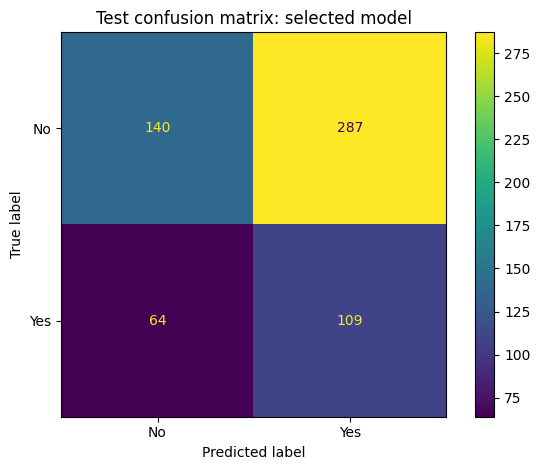

True negatives: 140 False positives: 287
False negatives: 64 True positives: 109


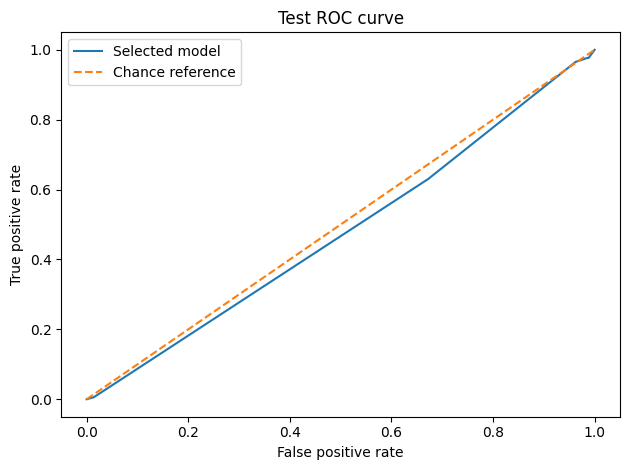

In [0]:
# Apply the same training-based scaling to test records without refitting.
X_test_scaled = scaler.transform(X_test)
# Generate readmission scores for the final test records.
test_probability = best_model.predict_proba(X_test_scaled)[:, 1]
# Convert test scores into predicted No/Yes outcomes at .5.
test_prediction = (test_probability >= 0.5).astype(int)
# Create an always-No rule for comparison.
baseline_prediction = np.zeros(len(y_test), dtype=int)
# Assign every patient the training readmission proportion as a constant-score baseline.
baseline_probability = np.repeat(y_train.mean(), len(y_test))
# Prepare the final model-versus-baseline results.
evaluation = []
# Evaluate the selected classifier and two constant prediction rules on the same test outcomes.
for name, prediction, probability in [
    # Include predictions from the selected model.
    ("Selected model", test_prediction, test_probability),
    # Include the baseline that predicts No for everyone.
    ("Always No", baseline_prediction, baseline_probability),
    # Include the baseline that predicts Yes for everyone.
    ("Always Yes", np.ones(len(y_test), dtype=int), np.ones(len(y_test)))]:
    # Calculate accuracy, precision, recall, F1 and probability-based ROC-AUC.
    evaluation.append({"Model": name,
        # Store the Accuracy value for this model.
        "Accuracy": accuracy_score(y_test, prediction),
        # Store the Precision value for this model.
        "Precision": precision_score(y_test, prediction, zero_division=0),
        # Store the Recall value for this model.
        "Recall": recall_score(y_test, prediction, zero_division=0),
        # Store the F1 value for this model.
        "F1": f1_score(y_test, prediction, zero_division=0),
        # Store the ROC-AUC value for this model.
        "ROC-AUC": roc_auc_score(y_test, probability)})
# Present the final test metrics together.
test_results = pd.DataFrame(evaluation)
# Display final test performance and baseline performance.
display(test_results)
# Show precision, recall, F1 and sample counts for each class.
print(classification_report(y_test, test_prediction,
    # Label the two outcome classes and display undefined metrics as zero.
    target_names=["Not readmitted", "Readmitted"], zero_division=0))
# Calculate confusion matrix
cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
# Plot the final test errors for the selected model.
ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(values_format="d")
# Give the chart a descriptive title.
plt.title("Test confusion matrix: selected model")
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()
# Extract the four counts for interpretation.
tn, fp, fn, tp = cm.ravel()
# Display correct non-readmissions and false alerts.
print("True negatives:", tn, "False positives:", fp)
# Display missed and correctly detected readmissions.
print("False negatives:", fn, "True positives:", tp)
# Calculate false-positive and true-positive rates across possible score thresholds.
fpr, tpr, thresholds = roc_curve(y_test, test_probability)
# Draw the selected model's test ROC curve.
plt.plot(fpr, tpr, label="Selected model")
# Add a chance-discrimination reference line.
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance reference")
# Label the horizontal axis.
plt.xlabel("False positive rate")
# Label the vertical axis.
plt.ylabel("True positive rate")
# Give the chart a descriptive title.
plt.title("Test ROC curve")
# Show the labels for the plotted lines or bars.
plt.legend()
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()


In [0]:
# Store the selected model's results for each data split.
split_results = []
# Use the same fixed model on training, validation and test records.
for name, data, target in [
    # Use the training records for this comparison.
    ("Training", X_train_scaled, y_train),
    # Use the validation records for this comparison.
    ("Validation", X_validation_scaled, y_validation),
    # Use the test records for this comparison.
    ("Test", X_test_scaled, y_test)]:
    # Estimate readmission probabilities for the current split.
    probability = best_model.predict_proba(data)[:, 1]
    # Classify scores using the fixed .5 threshold.
    prediction = (probability >= 0.5).astype(int)
    # Save F1, recall and ROC-AUC for comparison across splits.
    split_results.append({"Split": name,
        # Store the F1 value for this model.
        "F1": f1_score(target, prediction, zero_division=0),
        # Store the Recall value for this model.
        "Recall": recall_score(target, prediction, zero_division=0),
        # Store the ROC-AUC value for this model.
        "ROC-AUC": roc_auc_score(target, probability)})
# Display performance on training, validation and test records.
display(pd.DataFrame(split_results))


Split,F1,Recall,ROC-AUC
Training,0.4261501210653753,0.676923076923077,0.5460329026442308
Validation,0.3826086956521739,0.6358381502890174,0.4775283940924043
Test,0.38312829525483305,0.630057803468208,0.47750808842441544


**Observation**

The selected tuned decision tree identifies 109 of 173 actual readmissions and misses 64. It also flags 287 of 427 non-readmitted patients incorrectly. Test accuracy is 41.5%, precision 27.5%, recall 63.0%, F1 .383 and ROC-AUC .478. In total, 396 of 600 patients are flagged. The higher recall is obtained with many incorrect alerts, rather than reliable separation of the outcomes.

Always-No achieves 71.2% accuracy but identifies no readmissions. Always-Yes identifies every readmission and achieves F1 .448, exceeding the selected model's F1, while alerting on every patient. These comparisons show why neither accuracy nor F1 alone establishes a useful hospital tool. The selected model's test precision is below the test readmission proportion (28.8%), and ROC-AUC is near chance. The model comparison therefore has not demonstrated useful individual risk discrimination.

Training, validation and test F1 are .426, .383 and .383 respectively. A shallow tree reduces the large training-performance advantage seen in the unrestricted tree, but the discrimination remains weak. Class weighting changes the cost assigned to readmitted cases; it does not add predictive information. Restricted depth, larger leaf sizes and separate validation/test samples help control overfitting. Repeated splits, cross-validation and later independent hospital records would strengthen future evaluation.

The full dataset was explored for EDA and was used in earlier analyses, so these results are an internal project evaluation, not an independent external validation. No calibration analysis has been performed. Steyerberg et al. (2010) distinguish predictive discrimination from calibration and clinical usefulness; neither calibrated risk estimates nor clinical benefit is established here.

### Step 4: Feature Importance Analysis

Tree-based models provide feature importance scores, as in the original notebook. The chart compares the three original tree-based classifiers. It explains which variables those fitted models used most for splitting. It does not determine causality or establish statistical significance (Strobl et al., 2007).

Decision Tree,Gradient Boosting,Random Forest
0.03499458916892235,0.013935136148340613,0.026481594147535027
0.18089082391367972,0.15183186885204614,0.18946323251557448
0.17279139945832567,0.23489576395286527,0.20532119452896527
0.22661431627849282,0.31627877249027425,0.20514938311720893
0.035008544325869397,0.00934340243812053,0.02867700716200875
0.14226940313543393,0.12916957472394203,0.1602618368269376
0.09666390463481848,0.08502289341437796,0.10866221317159909
0.11076701908445757,0.05952258798003328,0.07598353853017085


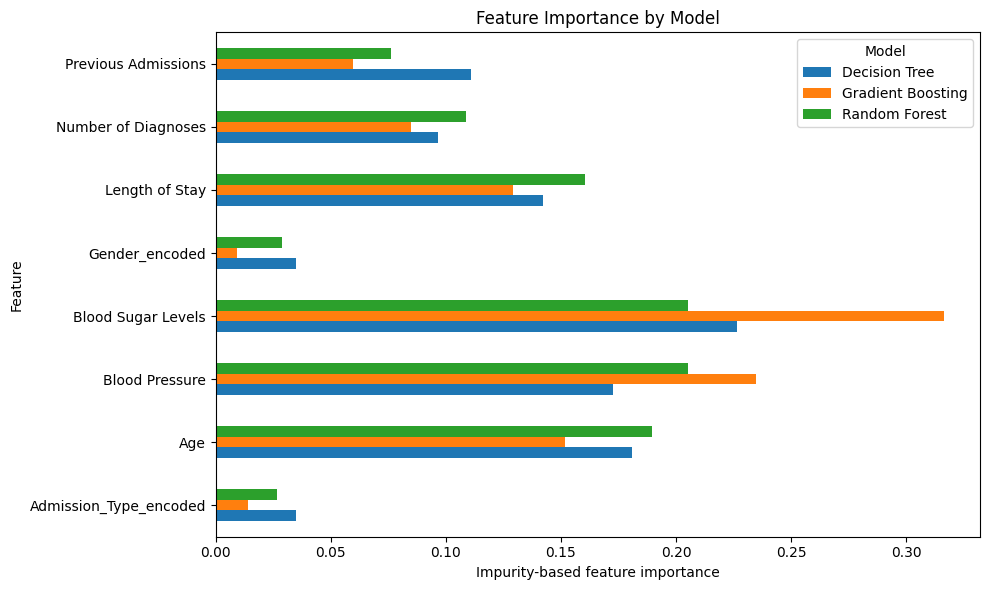

In [0]:
# Prepare a list to collect tree-based importance scores.
feature_importance_data = []
# Inspect the three fitted tree-based algorithms.
for name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    # Retrieve a fitted model without changing its learned parameters.
    model = trained_models[name]
    # Extract feature importance from tree-based models
    for feature, importance in zip(X.columns, model.feature_importances_):
        # Save each model-feature importance combination.
        feature_importance_data.append({"Model": name, "Feature": feature,
                                        # Store the Importance value for this model.
                                        "Importance": importance})
# Convert the collected importance scores into a table.
fi_df = pd.DataFrame(feature_importance_data)
# Arrange predictors as rows and classifiers as columns.
importance_table = fi_df.pivot(index="Feature", columns="Model", values="Importance")
# Display the importance score for each feature and tree model.
display(importance_table)
# Visualize feature importance for each tree-based model
importance_table.plot.barh(figsize=(10, 6))
# Label the horizontal axis.
plt.xlabel("Impurity-based feature importance")
# Give the chart a descriptive title.
plt.title("Feature Importance by Model")
# Adjust spacing so chart titles and labels fit.
plt.tight_layout()
# 7. Display the graph
plt.show()


**Observation**

Blood Sugar Levels, Blood Pressure and Age receive relatively large importance scores across the tree models. For example, random forest scores are approximately .205 for blood pressure, .205 for blood sugar and .189 for age. These rankings reflect split usage in fitted models, including models whose held-out performance is weak. Numeric variables also offer more possible split points than binary categories, a source of importance bias discussed by Strobl et al. (2007). These rankings cannot be presented to staff as evidence that these measurements are confirmed causes of readmission.

## Key Insights from Model Building

- **Multiple models:** Seven algorithms and three adjusted configurations were compared using the same data splits. Every configuration has all five test metrics, a classification report and a confusion matrix.
- **Model selection:** Validation F1 selected the tuned decision tree. Test metrics are reported after that decision and do not redefine the winner.
- **Overfitting:** The default decision tree and random forest achieved training F1 of 1.000 but much lower validation F1, illustrating that fitting training records well is not enough.
- **Readmission detection:** The selected candidate detected 109 of 173 test readmissions, missed 64 and produced 287 false alerts.
- **Baseline comparison:** Its test F1 of .383 was below the always-Yes baseline (.448), and ROC-AUC was .478. Selection among candidates therefore did not establish useful prediction.
- **Feature importance:** High split-importance scores indicate model usage, not confirmed clinical risk factors. Group rates and rankings remain exploratory.


## Implications for Hospital Staff

The aim is to identify patients who may need closer attention after discharge. Predictions inform this purpose only if the model reliably separates outcomes and the benefits of alerts outweigh missed cases and unnecessary work. Steyerberg et al. (2010) emphasise evaluating clinical usefulness when prediction models guide decisions.

The EDA identifies descriptive questions for further investigation. It does not establish that a demographic group or clinical measurement causes readmission. Model scores should not be presented as validated clinical risk probabilities. Hospital identity, label timing and measurement definitions need confirmation, and later patient records are needed for external evaluation. The current results determine whether the selected model provides useful discrimination; that cannot be assumed simply because several models were trained.

## Conclusion

This project explored 3,000 records and compared seven classification algorithms, with simple adjusted versions of three algorithms. Preprocessing found no missing values or duplicates. EDA showed overlapping numeric distributions and limited, inconsistent differences in group readmission rates. Eight original predictors were retained, excluding Patient ID and the target.

The tuned decision tree was selected using validation F1, then assessed on the test records. It detected 109 of 173 readmissions but produced 287 false alerts, with ROC-AUC .478. Its F1 also remained below an always-Yes baseline. It is the selected candidate under the comparison rule, but the results do not establish a useful model for hospital follow-up prioritisation.

The project answers whether the available data and tested methods can support prediction, rather than assuming that fitting a model means reliable hospital patterns have been learned. The present evidence supports improving data definitions and undertaking stronger validation before operational use. Group rates and feature rankings remain exploratory findings, not confirmed clinical concerns.

## References
Cawley, G.C. and Talbot, N.L.C. (2010) 'On over-fitting in model selection and subsequent selection bias in performance evaluation', *Journal of Machine Learning Research*, 11, pp. 2079–2107.

Futoma, J., Morris, J. and Lucas, J. (2015) 'A comparison of models for predicting early hospital readmissions', *Journal of Biomedical Informatics*, 56, pp. 229–238. doi: 10.1016/j.jbi.2015.05.016.

Saito, T. and Rehmsmeier, M. (2015) 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLOS ONE*, 10(3), article e0118432. doi: 10.1371/journal.pone.0118432.

Steyerberg, E.W., Vickers, A.J., Cook, N.R., Gerds, T., Gonen, M., Obuchowski, N., Pencina, M.J. and Kattan, M.W. (2010) 'Assessing the performance of prediction models: a framework for traditional and novel measures', *Epidemiology*, 21(1), pp. 128–138. doi: 10.1097/EDE.0b013e3181c30fb2.

Strobl, C., Boulesteix, A.-L., Zeileis, A. and Hothorn, T. (2007) 'Bias in random forest variable importance measures: illustrations, sources and a solution', *BMC Bioinformatics*, 8, article 25. doi: 10.1186/1471-2105-8-25.

